In [4]:
!pip install -q -U datasets pyarrow pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [5]:
from datasets import load_dataset
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import random

In [6]:
from datasets import load_dataset

base_url = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/resolve/"
    "a404451b48281f4e269be4bcb9899a7fa2275f87/"
)

data_files = [
    base_url + f"raw_review_Video_Games/full-0000{i}-of-00005.parquet"
    for i in range(5)
]

dataset = load_dataset(
    "parquet",
    data_files=data_files,
    split="train",
    streaming=True
)

print("Dataset berhasil diakses!")

Dataset berhasil diakses!


In [7]:
for i, row in enumerate(dataset.take(5)):
    print(f"\nReview ke-{i+1}")
    print("Rating:", row["rating"])
    print("Title:", row["title"])
    print("Text:", row["text"])
    print("Timestamp:", row["timestamp"])
    print("-" * 50)


Review ke-1
Rating: 4.0
Title: It’s pretty sexual. Not my fav
Text: I’m playing on ps5 and it’s interesting.  It’s unique, massive, and has a neat story.  People are freaking out angry about this game.  I don’t think it’s a top 10 game but it’s definitely a good game on ps5 (played at launch).
Timestamp: 1608186804795
--------------------------------------------------

Review ke-2
Rating: 5.0
Title: Good. A bit slow
Text: Nostalgic fun.  A bit slow.  I hope they don’t stretch it out too far.  It’s good tho
Timestamp: 1587051114941
--------------------------------------------------

Review ke-3
Rating: 5.0
Title: ... an order for my kids & they have really enjoyed playing this PC game
Text: This was an order for my kids & they have really enjoyed playing this PC game.
Timestamp: 1490877431000
--------------------------------------------------

Review ke-4
Rating: 5.0
Title: Great alt to pro controller
Text: These work great, They use batteries which is a bummer, but for the 40 less tha

In [8]:
print(dataset.features)

{'rating': Value('float64'), 'title': Value('string'), 'text': Value('string'), 'images': List({'attachment_type': Value('string'), 'large_image_url': Value('string'), 'medium_image_url': Value('string'), 'small_image_url': Value('string')}), 'asin': Value('string'), 'parent_asin': Value('string'), 'user_id': Value('string'), 'timestamp': Value('int64'), 'helpful_vote': Value('int64'), 'verified_purchase': Value('bool')}


In [10]:
import random
import pandas as pd
import numpy as np

from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

MAX_TRAIN_ROWS = 150_000
MAX_VALID_ROWS = 50_000

print("Configuration completed!")
print("Maximum training data:", MAX_TRAIN_ROWS)
print("Maximum validation data:", MAX_VALID_ROWS)

Configuration completed!
Maximum training data: 150000
Maximum validation data: 50000


In [12]:
# Reset sampling
train_samples = []
valid_samples = []

train_seen = 0
valid_seen = 0

SCAN_LIMIT = 300_000

MAX_TRAIN_ROWS = 30_000
MAX_VALID_ROWS = 10_000

random.seed(42)

for i, row in enumerate(tqdm(dataset.take(SCAN_LIMIT),
                              total=SCAN_LIMIT)):

    timestamp = int(row["timestamp"])

    # Maksimal 31 Desember 2019
    if timestamp > cutoff_ms:
        continue

    rating = float(row["rating"])

    # Label sentiment
    if rating in [1.0, 2.0]:
        label = 0
    elif rating in [4.0, 5.0]:
        label = 1
    else:
        continue

    title = row.get("title") or ""
    review = row.get("text") or ""

    combined_text = str(title).strip() + " " + str(review).strip()

    if not combined_text.strip():
        continue

    record = {
        "text": combined_text.strip(),
        "rating": rating,
        "timestamp": timestamp,
        "label": label
    }

    if timestamp < validation_start_ms:

        train_seen += 1

        reservoir_add(
            train_samples,
            record,
            train_seen,
            MAX_TRAIN_ROWS
        )

    else:

        valid_seen += 1

        reservoir_add(
            valid_samples,
            record,
            valid_seen,
            MAX_VALID_ROWS
        )

train_df = pd.DataFrame(train_samples)
valid_df = pd.DataFrame(valid_samples)

print("TRAINING:", len(train_df))
print("VALIDATION:", len(valid_df))

print("Eligible training:", train_seen)
print("Eligible validation:", valid_seen)

  0%|          | 0/300000 [00:00<?, ?it/s]

TRAINING: 30000
VALIDATION: 10000
Eligible training: 160112
Eligible validation: 29652


In [13]:
print("TRAINING DISTRIBUTION")
print(train_df["label"].value_counts())

print("\nVALIDATION DISTRIBUTION")
print(valid_df["label"].value_counts())

print("\nTRAINING DATE RANGE")
print(pd.to_datetime(
    train_df["timestamp"],
    unit="ms",
    utc=True
).agg(["min", "max"]))

print("\nVALIDATION DATE RANGE")
print(pd.to_datetime(
    valid_df["timestamp"],
    unit="ms",
    utc=True
).agg(["min", "max"]))

TRAINING DISTRIBUTION
label
1    25657
0     4343
Name: count, dtype: int64

VALIDATION DISTRIBUTION
label
1    8714
0    1286
Name: count, dtype: int64

TRAINING DATE RANGE
min          1999-11-13 03:03:29+00:00
max   2018-12-31 23:53:37.110000+00:00
Name: timestamp, dtype: datetime64[ns, UTC]

VALIDATION DATE RANGE
min   2019-01-01 01:00:18.987000+00:00
max   2019-12-31 23:46:17.732000+00:00
Name: timestamp, dtype: datetime64[ns, UTC]


Cell 1 — Save processed dataset

In [14]:
import os

os.makedirs("/content/data", exist_ok=True)

train_df.to_csv(
    "/content/data/train.csv",
    index=False
)

valid_df.to_csv(
    "/content/data/validation.csv",
    index=False
)

print("Training data saved!")
print("Validation data saved!")

Training data saved!
Validation data saved!


Cell 2 — Data quality checking

In [15]:
print("TRAINING CHECK")
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate reviews:")
print(train_df["text"].duplicated().sum())

print("\nVALIDATION CHECK")
print("Missing values:")
print(valid_df.isnull().sum())

print("\nDuplicate reviews:")
print(valid_df["text"].duplicated().sum())

print("\nLabel validation:")
print("Training:", sorted(train_df["label"].unique()))
print("Validation:", sorted(valid_df["label"].unique()))

TRAINING CHECK
Missing values:
text         0
rating       0
timestamp    0
label        0
dtype: int64

Duplicate reviews:
1983

VALIDATION CHECK
Missing values:
text         0
rating       0
timestamp    0
label        0
dtype: int64

Duplicate reviews:
461

Label validation:
Training: [np.int64(0), np.int64(1)]
Validation: [np.int64(0), np.int64(1)]


Cell 3 — EDA visualisasi

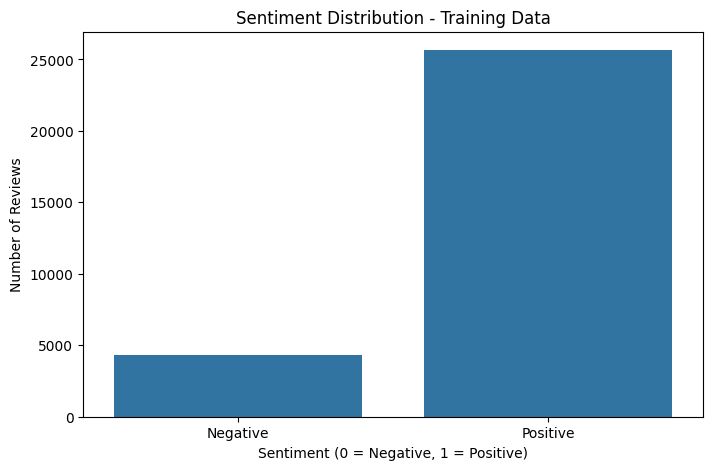

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="label"
)

plt.title("Sentiment Distribution - Training Data")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"])

plt.show()

1. Install dan import library

In [1]:
!pip install -q "python-dateutil>=2.8.2,<3" scikit-learn joblib matplotlib seaborn

In [2]:
import os
import random
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


2. Load dataset

In [3]:
train_df = pd.read_csv("/content/data/train.csv")
valid_df = pd.read_csv("/content/data/validation.csv")

print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

print("\nKolom dataset:")
print(train_df.columns.tolist())

print("\nContoh data training:")
print(train_df.head().to_string())

Training shape: (30000, 4)
Validation shape: (10000, 4)

Kolom dataset:
['text', 'rating', 'timestamp', 'label']

Contoh data training:
                                                                                                                                                                                                                                                                      text  rating      timestamp  label
0  died after one year of use These worked pretty well for a year with the only issue being that the mute button wouldn't always work.  The mic just died at one year.  The headphones still work, but at one year, it's frustrating to see it be worthless at this point.     1.0  1484880151000      0
1                                                                                                                                                           Easy for our grandchild to enter the code So simple to obtain!<br />Easy for our grandchild to enter the code.    

3. Data preparation

In [4]:
# Mengatasi missing value
train_df["text"] = train_df["text"].fillna("").astype(str)
valid_df["text"] = valid_df["text"].fillna("").astype(str)

train_df["label"] = train_df["label"].astype(int)
valid_df["label"] = valid_df["label"].astype(int)

# Menghapus teks kosong
train_df = train_df[train_df["text"].str.strip() != ""].copy()
valid_df = valid_df[valid_df["text"].str.strip() != ""].copy()

X_train = train_df["text"]
y_train = train_df["label"]

X_valid = valid_df["text"]
y_valid = valid_df["label"]

print("Jumlah data training:", len(X_train))
print("Jumlah data validation:", len(X_valid))

print("\nDistribusi label training:")
print(y_train.value_counts())

print("\nDistribusi label validation:")
print(y_valid.value_counts())

Jumlah data training: 30000
Jumlah data validation: 10000

Distribusi label training:
label
1    25657
0     4343
Name: count, dtype: int64

Distribusi label validation:
label
1    8714
0    1286
Name: count, dtype: int64


4. Visualisasi distribusi sentimen

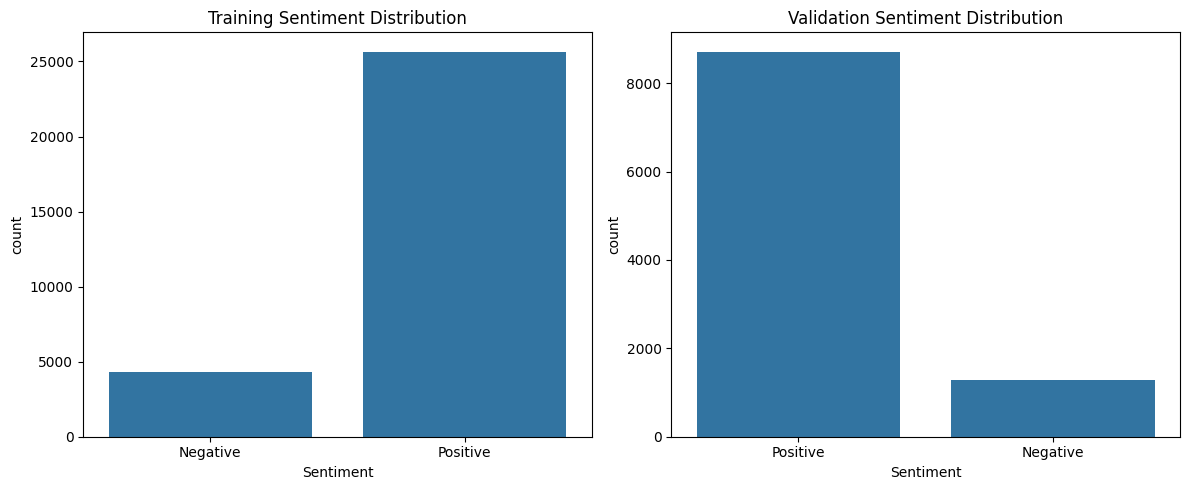

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    x=y_train.map({0: "Negative", 1: "Positive"}),
    ax=axes[0]
)
axes[0].set_title("Training Sentiment Distribution")
axes[0].set_xlabel("Sentiment")

sns.countplot(
    x=y_valid.map({0: "Negative", 1: "Positive"}),
    ax=axes[1]
)
axes[1].set_title("Validation Sentiment Distribution")
axes[1].set_xlabel("Sentiment")

plt.tight_layout()
plt.show()

5. Build model — TF-IDF + Logistic Regression
Kita menggunakan TF-IDF untuk mengubah teks menjadi representasi numerik, kemudian Logistic Regression untuk mengklasifikasikan sentimen.

class_weight="balanced" digunakan untuk membantu mengatasi ketidakseimbangan jumlah kelas.

In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        strip_accents="unicode",
        dtype=np.float32
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    ))
])

print("Model berhasil dibuat!")

Model berhasil dibuat!


6. Training model

In [7]:
print("Mulai training model...")

model.fit(X_train, y_train)

print("Training selesai!")

Mulai training model...
Training selesai!


7. Prediction

In [8]:
y_pred = model.predict(X_valid)

print("Prediksi berhasil dilakukan!")

print("\nContoh hasil prediksi:")

prediction_result = pd.DataFrame({
    "Actual": y_valid.values[:10],
    "Predicted": y_pred[:10]
})

prediction_result["Actual"] = prediction_result["Actual"].map({
    0: "Negative",
    1: "Positive"
})

prediction_result["Predicted"] = prediction_result["Predicted"].map({
    0: "Negative",
    1: "Positive"
})

print(prediction_result)

Prediksi berhasil dilakukan!

Contoh hasil prediksi:
     Actual Predicted
0  Positive  Positive
1  Positive  Positive
2  Positive  Positive
3  Positive  Positive
4  Positive  Positive
5  Positive  Positive
6  Negative  Negative
7  Negative  Negative
8  Positive  Positive
9  Positive  Positive


8. Model evaluation
Macro-F1 menjadi metrik evaluasi utama sesuai brief tugas.

In [9]:
accuracy = accuracy_score(y_valid, y_pred)

precision_macro = precision_score(
    y_valid, y_pred, average="macro"
)

recall_macro = recall_score(
    y_valid, y_pred, average="macro"
)

f1_macro = f1_score(
    y_valid, y_pred, average="macro"
)

print("=" * 45)
print("MODEL EVALUATION")
print("=" * 45)

print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall   : {recall_macro:.4f}")
print(f"Macro F1-Score : {f1_macro:.4f}")

MODEL EVALUATION
Accuracy       : 0.9451
Macro Precision: 0.8566
Macro Recall   : 0.9360
Macro F1-Score : 0.8901


9. Classification report

In [10]:
print(classification_report(
    y_valid,
    y_pred,
    target_names=["Negative", "Positive"],
    digits=4
))

              precision    recall  f1-score   support

    Negative     0.7248    0.9238    0.8123      1286
    Positive     0.9883    0.9482    0.9678      8714

    accuracy                         0.9451     10000
   macro avg     0.8566    0.9360    0.8901     10000
weighted avg     0.9544    0.9451    0.9478     10000



10. Confusion matrix

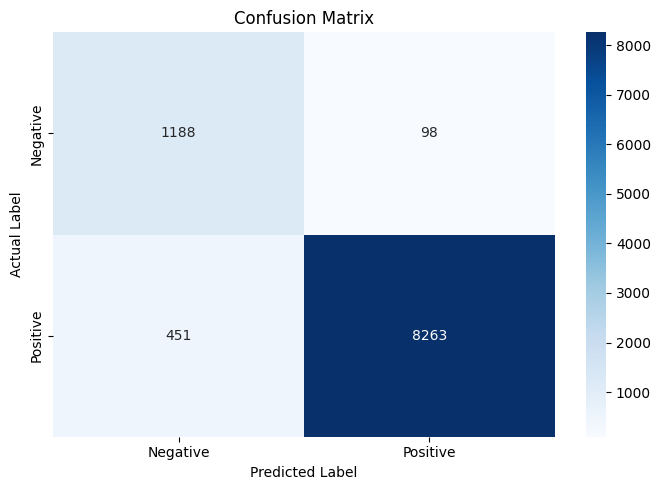

In [11]:
cm = confusion_matrix(y_valid, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

11. Simpan model

In [12]:
os.makedirs("/content/models", exist_ok=True)

model_path = "/content/models/amazon_sentiment_model.joblib"

joblib.dump(model, model_path)

print("Model berhasil disimpan!")
print("Lokasi:", model_path)

Model berhasil disimpan!
Lokasi: /content/models/amazon_sentiment_model.joblib


12. Load ulang model
Bagian ini membuktikan bahwa model yang sudah disimpan bisa digunakan kembali.

In [13]:
loaded_model = joblib.load(
    "/content/models/amazon_sentiment_model.joblib"
)

print("Model berhasil di-load ulang!")

test_prediction = loaded_model.predict(X_valid[:5])

print("\nHasil pengujian:")
for i, prediction in enumerate(test_prediction):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print(f"Review {i+1}: {sentiment}")

Model berhasil di-load ulang!

Hasil pengujian:
Review 1: Positive
Review 2: Positive
Review 3: Positive
Review 4: Positive
Review 5: Positive


13. Custom sentiment prediction

In [14]:
def predict_sentiment(review):
    prediction = loaded_model.predict([review])[0]
    probabilities = loaded_model.predict_proba([review])[0]

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probabilities[prediction] * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Confidence: {confidence:.2f}%")

    return sentiment


# Contoh pengujian
predict_sentiment(
    "This game is amazing, the graphics are beautiful "
    "and the gameplay is very enjoyable."
)

print("\n" + "-" * 50 + "\n")

predict_sentiment(
    "The game is terrible, full of bugs and very disappointing."
)

Review: This game is amazing, the graphics are beautiful and the gameplay is very enjoyable.
Predicted Sentiment: Positive
Confidence: 80.20%

--------------------------------------------------

Review: The game is terrible, full of bugs and very disappointing.
Predicted Sentiment: Negative
Confidence: 96.52%


'Negative'

14. Simpan hasil evaluasi

In [15]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Score": [
        accuracy,
        precision_macro,
        recall_macro,
        f1_macro
    ]
})

evaluation_results.to_csv(
    "/content/models/evaluation_results.csv",
    index=False
)

print(evaluation_results.to_string(index=False))

         Metric    Score
       Accuracy 0.945100
Macro Precision 0.856556
   Macro Recall 0.936019
 Macro F1-Score 0.890078
